In [ ]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
import glob
from bs4 import BeautifulSoup
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
import joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/CW_NC'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
os.listdir(BASE_PATH)

['OLD',
 'reuters+21578+text+categorization+collection.zip',
 'X_test_tfidf.pkl',
 'y_test_enc.pkl',
 'y_train_enc.pkl',
 'X_train_tfidf.pkl',
 'TextMLP_new.ipynb',
 'SVM.ipynb',
 'DATA_PREP.ipynb',
 'TextMLP.ipynb',
 'X_train_prob.pkl',
 'X_test_prob.pkl']

DATA LOAD (Adaped from Computer Vision Lab)

In [ ]:
# Identify path to zipped dataset
zip_path = os.path.join(BASE_PATH, 'reuters+21578+text+categorization+collection.zip')

# Copy it to Colab (using the Python variable directly)
!cp -f {zip_path} .

# Unzip it (-q for quiet, -o for overwrite)
!unzip -qo reuters+21578+text+categorization+collection.zip

# Delete zipped version from Colab local storage
!rm reuters+21578+text+categorization+collection.zip

print("Coursework dataset extracted successfully!")

Coursework dataset extracted successfully!


In [ ]:
import tarfile

#Extracting zip file(unpacking)
# List files inside tar.gz
with tarfile.open("/content/reuters21578.tar.gz", "r:gz") as tar:
    print(tar.getnames())

['README.txt', 'all-exchanges-strings.lc.txt', 'all-orgs-strings.lc.txt', 'all-people-strings.lc.txt', 'all-places-strings.lc.txt', 'all-topics-strings.lc.txt', 'cat-descriptions_120396.txt', 'feldman-cia-worldfactbook-data.txt', 'lewis.dtd', 'reut2-000.sgm', 'reut2-001.sgm', 'reut2-002.sgm', 'reut2-003.sgm', 'reut2-004.sgm', 'reut2-005.sgm', 'reut2-006.sgm', 'reut2-007.sgm', 'reut2-008.sgm', 'reut2-009.sgm', 'reut2-010.sgm', 'reut2-011.sgm', 'reut2-012.sgm', 'reut2-013.sgm', 'reut2-014.sgm', 'reut2-015.sgm', 'reut2-016.sgm', 'reut2-017.sgm', 'reut2-018.sgm', 'reut2-019.sgm', 'reut2-020.sgm', 'reut2-021.sgm']


In [ ]:
# Extract only .sgm files
!mkdir reuters_sgm
!tar -xvzf reuters21578.tar.gz -C reuters_sgm --wildcards 'reut2-*.sgm'

mkdir: cannot create directory ‘reuters_sgm’: File exists
reut2-000.sgm
reut2-001.sgm
reut2-002.sgm
reut2-003.sgm
reut2-004.sgm
reut2-005.sgm
reut2-006.sgm
reut2-007.sgm
reut2-008.sgm
reut2-009.sgm
reut2-010.sgm
reut2-011.sgm
reut2-012.sgm
reut2-013.sgm
reut2-014.sgm
reut2-015.sgm
reut2-016.sgm
reut2-017.sgm
reut2-018.sgm
reut2-019.sgm
reut2-020.sgm
reut2-021.sgm


DATA READ

In [ ]:
files = glob.glob("/content/reuters_sgm/reut2-*.sgm")

In [ ]:
def parse_file(file):
    with open(file, 'r', encoding='latin-1') as f:
        data = f.read()

    soup = BeautifulSoup(data, "lxml")
    return soup.find_all("reuters")

In [ ]:
all_articles = []
for file in files:
    articles = parse_file(file)
    all_articles.extend(articles)

print(f"Total articles found: {len(all_articles)}")

Total articles found: 21578


In [ ]:
all_articles[9]

<reuters cgisplit="TRAINING-SET" lewissplit="TRAIN" newid="5010" oldid="9923" topics="NO">
<date>13-MAR-1987 15:21:47.30</date>
<topics></topics>
<places><d>usa</d></places>
<people></people>
<orgs></orgs>
<exchanges></exchanges>
<companies></companies>
<unknown> 
F
f0265reute
r f BC-COMMERCE-BANCORP-&lt;COB   03-13 0095</unknown>
<text>
<title>COMMERCE BANCORP &lt;COBA&gt; FILES FOR OFFERING</title>
<dateline>    CHERRY HILL, N.J., March 13 - </dateline>Commerce Bancorp Inc said it
has filed a registration statement with the Securities and
Exchange Commission for a 575,000 share Series B cumulative
preferred stock offering, including 75,000 shares to cover
allotments.
    Commerce said it and its banking subsidiaries will use the
proceeds to support their planned growth and for general
corporate purposes.
    The bank holding company said each share of preferred
stocks initially will be convertible into one share of Commerce
common stock.
    Commerce said the preferred shares

In [ ]:
all_articles[2].find('title')

<title>USDA REPORTS 10.572 MLN ACRES IN CONSERVATION</title>

RELEVANT DATA EXTRACTION

In [ ]:
#AI was used to extract the required text, topic and title of the article
def extract_article_data(article):

    title      = article.find('title')
    title_text = title.text.strip() if title else ''

    text_tag  = article.find('text')
    body_text = ''

    if text_tag:
        raw     = str(text_tag)
        pattern = r"(?<=</dateline>)(.*?)(?=\s+Reuter)"
        match   = re.search(pattern, raw, re.DOTALL)

        if match:
            body_text = match.group(1).strip()
        else:
            body_text = ""

    topics_tag = article.find('topics')
    topics     = [d.text for d in topics_tag.find_all('d')] if topics_tag else []

    return {
        'title'      : title_text,
        'body'       : body_text,
        'topics'     : topics,
    }

In [ ]:
#Creating dataframe of extracted information
def build_dataframe(data_path='/content/reuters_sgm/*.sgm'):
    all_articles = []

    # Get all sgm files
    files = glob.glob(data_path)
    print(f"Found {len(files)} files")

    # Parse each file
    for file in files:
        articles = parse_file(file)
        for article in articles:
            article_data = extract_article_data(article)
            all_articles.append(article_data)

    # Create DataFrame
    df = pd.DataFrame(all_articles)
    return df

In [ ]:
df = build_dataframe()
print(f"Total articles: {len(df)}")
df.head()

Found 22 files
Total articles: 21578


,lewissplit,title,body,topics
0,TRAIN,PLM <PLMA> UNIT ENDS MERGER TALKS,PLM Cos Inc said its PLM Power Co\nunit broke ...,[acq]
1,TRAIN,COLOMBIA OPENS APRIL/MAY COFFEE REGISTRATIONS,Colombia opened coffee export\nregistrations f...,[coffee]
2,TRAIN,USDA REPORTS 10.572 MLN ACRES IN CONSERVATION,The U.S. Agriculture Department has\naccepted ...,"[grain, corn]"
3,TRAIN,BRAZIL DEBT POSES THORNY ISSUE FOR U.S. BANKS,CitiCorp &lt;CCI&gt; appears to be digging\nin...,[]
4,TRAIN,ROCKWELL <ROK> TO REPURCHASE MORE COMMON SHARES,Rockwell International Corp said its\nboard ha...,[]


In [ ]:
unique_topics = df['topics'].explode().dropna().unique()

#Convert to a sorted list
unique_topics_list = sorted(list(unique_topics))

print(f"Total unique topics: {len(unique_topics_list)}")
print(unique_topics_list)

Total unique topics: 120
['acq', 'alum', 'austdlr', 'barley', 'bfr', 'bop', 'can', 'carcass', 'castor-oil', 'castorseed', 'citruspulp', 'cocoa', 'coconut', 'coconut-oil', 'coffee', 'copper', 'copra-cake', 'corn', 'corn-oil', 'cornglutenfeed', 'cotton', 'cotton-oil', 'cottonseed', 'cpi', 'cpu', 'crude', 'cruzado', 'dfl', 'dkr', 'dlr', 'dmk', 'earn', 'f-cattle', 'fishmeal', 'fuel', 'gas', 'gnp', 'gold', 'grain', 'groundnut', 'groundnut-oil', 'heat', 'hk', 'hog', 'housing', 'income', 'instal-debt', 'interest', 'inventories', 'ipi', 'iron-steel', 'jet', 'jobs', 'l-cattle', 'lead', 'lei', 'lin-meal', 'lin-oil', 'linseed', 'lit', 'livestock', 'lumber', 'meal-feed', 'money-fx', 'money-supply', 'naphtha', 'nat-gas', 'nickel', 'nkr', 'nzdlr', 'oat', 'oilseed', 'orange', 'palladium', 'palm-oil', 'palmkernel', 'peseta', 'pet-chem', 'platinum', 'plywood', 'pork-belly', 'potato', 'propane', 'rand', 'rape-meal', 'rape-oil', 'rapeseed', 'red-bean', 'reserves', 'retail', 'rice', 'ringgit', 'rubber', '

In [ ]:
df.shape

(21578, 4)

In [ ]:
df[df.body==""]

,lewissplit,title,body,topics
16,TRAIN,"U.S. EXPORTERS REPORT 122,000 TONNES CORN SOL...",,"[grain, corn]"
23,TRAIN,S/P UPGRADES UNION CARBIDE CORP'S 1.2 BILLION ...,,[]
24,TRAIN,ELECTRICITE DE FRANCE SAYS IT WILL LAUNCH EURO...,,[]
45,TRAIN,JOHN LABATT LTD 3RD QTR SHR DILUTED 32 CTS VS ...,,[earn]
58,TRAIN,U.S. BUSINESS LOANS RISE 377 MLN DLRS IN MARCH...,,[money-supply]
...,...,...,...,...
21541,TRAIN,HUGHES TOOL SHAREHOLDERS APPROVE MERGER WITH B...,,[acq]
21552,TRAIN,"S/P DOWNGRADES BAKER INTERNATIONAL CORP, UPGRA...",,[]
21553,TRAIN,"EIA SAYS DISTILLATE STOCKS OFF 8.8 MLN, GASOLI...",,[crude]
21560,TRAIN,HARPER AND ROW GETS BID FROM HARCOURT BRACE JO...,,[acq]


In [ ]:
df_topic = df[df["topics"].map(len) > 0].copy()
df_topic.shape

(11367, 4)

In [ ]:
df_topic.head()

,lewissplit,title,body,topics
0,TRAIN,PLM <PLMA> UNIT ENDS MERGER TALKS,PLM Cos Inc said its PLM Power Co\nunit broke ...,[acq]
1,TRAIN,COLOMBIA OPENS APRIL/MAY COFFEE REGISTRATIONS,Colombia opened coffee export\nregistrations f...,[coffee]
2,TRAIN,USDA REPORTS 10.572 MLN ACRES IN CONSERVATION,The U.S. Agriculture Department has\naccepted ...,"[grain, corn]"
8,TRAIN,U.S. MEAT GROUP TO FILE TRADE COMPLAINTS,"The American Meat Institute, AME,\nsaid it int...","[livestock, carcass]"
11,TRAIN,MET-PRO CORP <MPR> TO PAY REGULAR DIVIDEND,Qtrly 15 cts vs 15 cts prior\n Pay May Eigh...,[earn]


Converting the Non-Atomic Topic feature to atomic

In [ ]:
df_topic.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11367 entries, 0 to 21577
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   lewissplit  11367 non-null  object
 1   title       11367 non-null  object
 2   body        11367 non-null  object
 3   topics      11367 non-null  object
dtypes: object(4)
memory usage: 444.0+ KB


In [ ]:
# Get top 15 topics
all_topics = [t for row in df_topic['topics'] for t in row]
topic_counts = Counter(all_topics)

TOP_N = 10
top_20 = set([cls for cls, _ in topic_counts.most_common(TOP_N)])

print("Top 15 topics:")
for cls, count in topic_counts.most_common(TOP_N):
    print(f"  {cls:20} {count}")

Top 15 topics:
  earn                 3987
  acq                  2448
  money-fx             801
  crude                634
  grain                628
  trade                552
  interest             513
  wheat                306
  ship                 305
  corn                 254


Text(0.5, 1.0, 'Top 10 Topics')

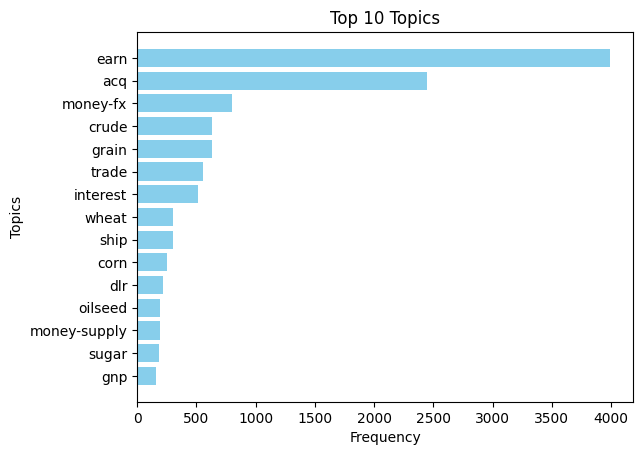

In [ ]:
top_n_data = topic_counts.most_common(15)

# 2. Prepare data for plotting
# Unpack the tuples into two lists
topics, counts = zip(*top_n_data)
topics = list(topics)[::-1]
counts = list(counts)[::-1]

# 3. Create the plot
plt.barh(topics, counts, color='skyblue')
plt.xlabel('Frequency')
plt.ylabel('Topics')
plt.title(f'Top {TOP_N} Topics')

In [ ]:
results = []

for idx, row in df_topic.iterrows():
    topics    = row['topics']
    top10_hits = [t for t in topics if t in top_20]

    # No top 10 topics in this row → drop
    if len(top10_hits) == 0:
        continue

    # Single topic row → use it directly
    elif len(topics) == 1:
        label = topics[0]

    # Multi topic row → pick least frequent top 10 hit
    else:
        label = min(top10_hits, key=lambda t: topic_counts[t])

    results.append({
        'lewissplit'  : row['lewissplit'],
        'title'       : row['title'],
        'body'        : row['body'],
        'orig_topics' : topics,
        'label'       : label,
    })

df_result = pd.DataFrame(results)

print(f"Rows kept    : {len(df_result)}")
print(f"Rows dropped : {len(df_topic) - len(df_result)}")
print(f"\nLabel distribution:\n{df_result['label'].value_counts().to_string()}")

Rows kept    : 9400
Rows dropped : 1967

Label distribution:
label
earn        3953
acq         2412
money-fx     553
crude        548
trade        532
interest     513
ship         300
corn         253
wheat        214
grain        122


In [ ]:
df_result.shape

(9400, 5)

TEXT PREPROCESSING

In [ ]:
df_result.shape

(9400, 5)

Combining title and body text

In [ ]:
df_combined = df_result.copy()
df_combined=df_combined[~(df_combined['title']=="")]
df_combined.shape

(9350, 5)

In [ ]:
df_combined['text'] = df_combined['title'] + ' ' + df_combined['body']
df_combined.shape

(9350, 6)

In [ ]:
df_combined[df_combined['text'].str.len() < 30]

,lewissplit,label,text
1454,TRAIN,earn,<daewoo corp> calendar 1986
1621,TRAIN,earn,cra ltd <craa.s> 1986 net
2143,TEST,earn,c. itoh and co ltd <citt.t>
2460,TRAIN,earn,britoil plc <btol.l> 1986 yr
3096,TRAIN,acq,akzo planning us investments
3351,TRAIN,acq,u.k. merger clearances
3373,TRAIN,earn,sun life assurance profit up
3769,TRAIN,earn,sandoz ag <sanz.z> year 1986
3773,TRAIN,earn,alusuisse <aluz.z> year 1986
4014,TRAIN,earn,bicc plc <bicc.l> 1986 year


In [ ]:
df_combined['text']

,text
0,plm <plma> unit ends merger talks plm cos inc ...
1,usda reports 10.572 mln acres in conservation ...
2,met-pro corp <mpr> to pay regular dividend qtr...
3,aileen inc <aee> 1sr qtr jan 31 loss shr loss ...
4,wolverine world wide inc <www> 4th qtr loss sh...
...,...
9395,lionel corp <lio> 4th qtr jan 31 oper net oper...
9396,recent u.s. oil demand up 1.9 pct from year ag...
9397,"(montreal city, district savings bank) 1st qtr..."
9398,businessman has 8.9 pct of del e. webb <dwp.a>...


In [ ]:
df_combined.shape

(9350, 3)

In [ ]:
df_combined.drop(columns=['title','body','orig_topics'],inplace=True) #dropped columns after combining data into text feature
df_combined.sample(5)

KeyError: "['title', 'body', 'orig_topics'] not found in axis"

In [ ]:
df_combined.iloc[1491]

,1500
lewissplit,TRAIN
label,earn
text,DURO-TEST CORP <DUR> 2ND QTR JAN 31 NET Shr 10...


In [ ]:
df_combined.shape

(9350, 3)

In [ ]:
df_combined.sample(10)

,lewissplit,label,text
2962,TRAIN,earn,johnson electronics inc <jhsn> 4th qtr loss sh...
319,TRAIN,acq,lynch corp <lgl> unit buys television station ...
7424,TEST,earn,data med clinical support<dmcs.o> 1st qtr loss...
1972,TEST,earn,rjr nabisco first quarter net to include 208 m...
7268,NOT-USED,ship,panama canal unaffected by political protest
5733,TEST,acq,fluorocarbon <fcbn.o> completes acquisition fl...
1788,TEST,earn,airsensors inc <arsn> 3rd qtr jan 31 loss shr ...
7458,TEST,trade,chilean trade surplus narrows slightly in febr...
8125,TRAIN,earn,<westar mining ltd> 4th qtr loss shr not given...
6153,TRAIN,money-fx,sumita says he does not expect further dollar ...


In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove unicode characters
    text = text.encode('ascii', 'ignore').decode('ascii')

    # Handle CamelCase
    text = re.sub(r'([a-z])([A-Z])', r'\1 \2', text)

    # Remove emoticons
    text = re.sub(r'[:;=8][\-o\*\']?[\)\]\(\[dDpP/\:\}\{@\|\\]', '', text)

    # Remove digits
    text = re.sub(r'\d+', '', text)

    # Remove special characters and punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
from nltk.corpus import stopwords
StopWords = set(stopwords.words('english'))

def tokenize_and_stem(text):
    stemmer = PorterStemmer()

    #Tokenize
    tokens = word_tokenize(text)

    #Stem & stopword
    processed_tokens = [stemmer.stem(word) for word in tokens if word not in StopWords]

    #Rejoin into a single string for Vectorization
    return " ".join(processed_tokens)

In [ ]:
# Execute the pipeline
df_combined_clean = df_combined.copy()

# Step A: Noise Removal
df_combined_clean['text'] = df_combined_clean['text'].apply(clean_text)

In [ ]:
# This filters for rows where the string length is less than 3
df_combined_clean[df_combined_clean['text'].str.len() < 30]

,lewissplit,label,text
270,TRAIN,earn,gencorp st qtr shr cts vs cts
414,TRAIN,earn,ccic finance ltd year to dec
1454,TRAIN,earn,daewoo corp calendar
1621,TRAIN,earn,cra ltd craas net
1623,TRAIN,earn,comalco ltd cmacs net
1625,TRAIN,earn,fisons plc fisnl year to end
1633,TRAIN,earn,stc plc stcll year to end
1864,TEST,acq,mepc extends offer for oldham
1867,TEST,earn,aegon net profit rises pct
2143,TEST,earn,c itoh and co ltd cittt


In [ ]:
df_combined_clean

,lewissplit,label,text
0,TRAIN,acq,plm plma unit ends merger talks plm cos inc sa...
1,TRAIN,corn,usda reports mln acres in conservation the us ...
2,TRAIN,earn,metpro corp mpr to pay regular dividend qtrly ...
3,TRAIN,earn,aileen inc aee sr qtr jan loss shr loss cts vs...
4,TRAIN,earn,wolverine world wide inc th qtr loss shr loss ...
...,...,...,...
9395,TRAIN,earn,lionel corp lio th qtr jan oper net oper shr d...
9396,TRAIN,crude,recent us oil demand up pct from year ago us o...
9397,TRAIN,earn,montreal city district savings bank st qtr shr...
9398,TRAIN,acq,businessman has pct of del e webb dwpa john co...


In [ ]:
df_combined_clean.iloc[20]['text']

'wheeling and lake erie railway co wle div qtly div dlrs vs dlrs pay may record april note dividend paid to all shareholders other than norfolk southern corps ltnscgt norfolk and western railway co'

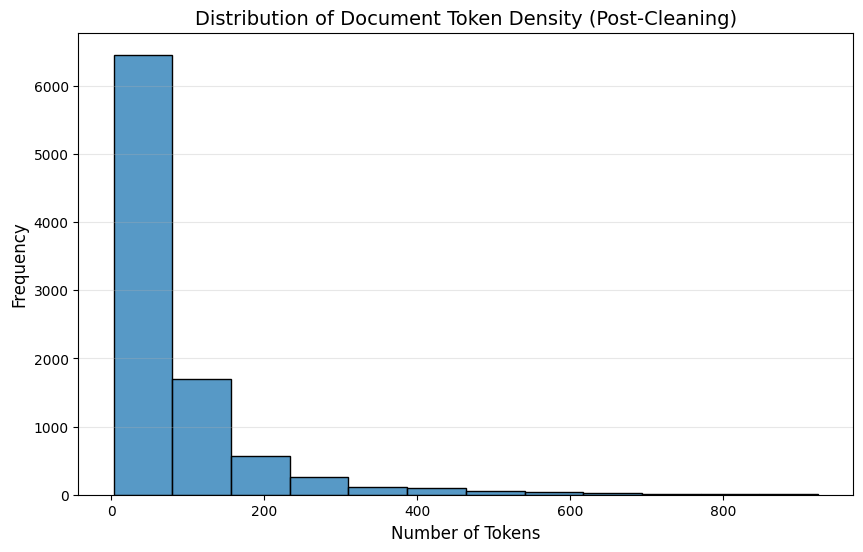

In [ ]:
#Calculate the number of tokens per document
token_cnt = df_combined_clean['text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
sns.histplot(token_cnt,bins=12)

plt.title('Distribution of Document Token Density (Post-Cleaning)', fontsize=14)
plt.xlabel('Number of Tokens', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
# plt.xticks([2,4,6,8,10,12,14,16,18,20,22,24])
plt.show()

In [ ]:
df_combined_clean.label.unique()

array(['acq', 'corn', 'earn', 'crude', 'wheat', 'trade', 'money-fx',
       'interest', 'ship', 'grain'], dtype=object)

Word Cloud for topic text analysis

In [1]:
#AI was used to generate the word cloud for the text in the article of particular topic
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def generate_topic_wordclouds(df, topic_column='label', text_column='text'):
    # Get the unique topics (assumes you have 3 based on your request)
    topics = ['earn','interest','crude']

    # Set up the figure
    fig, axes = plt.subplots(1, 3, figsize=(20, 10))

    for i, topic in enumerate(topics):
        #Combine all rows for this specific topic into one large string
        topic_text = " ".join(df[df[topic_column] == topic][text_column])

        #Create the WordCloud object
        wordcloud = WordCloud(
            width=800,
            height=800,
            background_color='white',
            colormap='viridis',
            min_font_size=10
        ).generate(topic_text)

        #Plot
        axes[i].imshow(wordcloud, interpolation='bilinear')
        axes[i].set_title(f'Topic: {topic}', fontsize=20)
        axes[i].axis("off")

    plt.tight_layout(pad=0)
    plt.show()
generate_topic_wordclouds(df_combined_clean)

NameError: name 'df_combined_clean' is not defined

In [ ]:
# Step B: Tokenize -> Stem -> Rejoin
df_combined_clean['text'] = df_combined_clean['text'].apply(tokenize_and_stem)

In [ ]:
df_combined_clean.sample(10)

,lewissplit,label,text
2707,TRAIN,acq,guin start court action saunder
3451,TRAIN,earn,bank british columbia st qtr jan net oper shr ...
310,TRAIN,earn,philip crosbi associ pca earn delay philip cro...
6611,TRAIN,acq,bishop graphic bgph complet store sale bishop ...
6954,TRAIN,acq,fc laboratori fcsi termin deal talk fc laborat...
810,TRAIN,acq,macandrewsforb unit begin offer buy revlon gro...
3253,TRAIN,acq,safetykleen sk complet acquisit safetykleen co...
2022,TEST,earn,fitchburg ga fge rais quarterli qtli div ct vs...
5203,TEST,earn,coeur dalen mine corp couro rd qtr net shr pro...
8748,TRAIN,earn,altex resourc ltd year net shr six ct vs eight...


In [ ]:
df_combined_clean.shape

(9350, 3)

In [ ]:
from sklearn.model_selection import train_test_split

#Split into Train (70%) and Temp (30%)
X_train, X_test, y_train, y_test = train_test_split(
    df_combined_clean['text'],
    df_combined_clean['label'],
    test_size=0.30,
    random_state=45,
    stratify=df_combined_clean['label']
)

print(f"Train size: {len(X_train)}")
# print(f"Val size: {len(X_val)}")
print(f"Test size: {len(X_test)}")

Train size: 6545
Test size: 2805


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder() #converting text to integers
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)
num_classes = len(le.classes_)

In [ ]:
len(le.classes_)

10

In [ ]:
y_train.shape

(6545,)

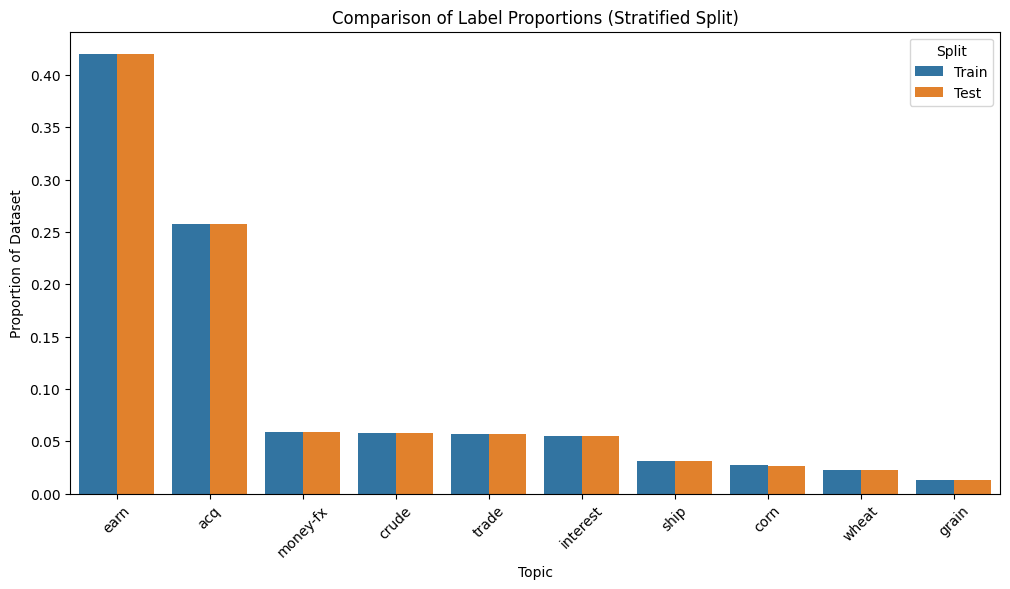

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create a temporary DataFrame for plotting
train_dist = y_train.value_counts(normalize=True).reset_index()
train_dist['Split'] = 'Train'

test_dist = y_test.value_counts(normalize=True).reset_index()
test_dist['Split'] = 'Test'

# Combine them
compare_df = pd.concat([train_dist, test_dist])
compare_df.columns = ['Topic', 'Percentage', 'Split']

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=compare_df, x='Topic', y='Percentage', hue='Split')
plt.title('Comparison of Label Proportions (Stratified Split)')
plt.xticks(rotation=45)
plt.ylabel('Proportion of Dataset')
plt.show()

In [ ]:
#AI was used to replicate the weighted TF-IDF as suggested in the paper

import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

# ── Step 1: Get raw term counts ───────────────────────────────
count_vec      = CountVectorizer(max_features=1500)
X_train_counts = count_vec.fit_transform(X_train)   # fit on train only
X_test_counts  = count_vec.transform(X_test)

# ── Step 2: Compute probability-based weights per term ────────
n_terms      = X_train_counts.shape[1]
classes      = np.unique(y_train_enc)
prob_weights = np.zeros(n_terms)

# Binary occurrence matrix — 1 if term appears in doc, 0 otherwise
term_occur = (X_train_counts > 0).toarray()        # shape: (n_docs, n_terms)

for c in classes:
    in_class = (y_train_enc == c).astype(int)       # 1 if doc is class c

    # A: docs IN class c where term occurs
    A = (term_occur *  in_class[:, None]).sum(axis=0)

    # B: docs NOT IN class c where term occurs
    B = (term_occur * (1 - in_class[:, None])).sum(axis=0)

    # C: docs IN class c where term does NOT occur
    C = ((1 - term_occur) * in_class[:, None]).sum(axis=0)

    # Avoid division by zero
    B = np.maximum(B, 1)
    C = np.maximum(C, 1)

    # Relevance indicator for this class — paper's formula
    prob_weights += np.log(1 + (A / B) * (A / C))

# Average relevance across all classes
prob_weights /= len(classes)

# ── Step 3: Apply tf × prob_weight ───────────────────────────
# Log-normalised TF (same as standard TF-IDF uses internally)
X_train_tf = np.log1p(X_train_counts.toarray().astype(float))
X_test_tf  = np.log1p(X_test_counts.toarray().astype(float))

X_train_prob = X_train_tf * prob_weights            # shape: (n_train, 1500)
X_test_prob  = X_test_tf  * prob_weights            # shape: (n_test,  1500)

print(f"Train shape : {X_train_prob.shape}")
print(f"Test shape  : {X_test_prob.shape}")

Train shape : (6545, 1500)
Test shape  : (2805, 1500)


#### Saving Preprocessed Data

In [ ]:
joblib.dump(X_train_prob, '/content/drive/MyDrive/CW_NC/X_train_prob.pkl')
joblib.dump(X_test_prob, '/content/drive/MyDrive/CW_NC/X_test_prob.pkl')

['/content/drive/MyDrive/CW_NC/X_test_prob.pkl']

In [ ]:
joblib.dump(y_test_enc, '/content/drive/MyDrive/CW_NC/y_test_enc.pkl')
joblib.dump(y_train_enc,'/content/drive/MyDrive/CW_NC/y_train_enc.pkl')

['/content/drive/MyDrive/CW_NC/y_train_enc.pkl']